# 1 Importing Packages

How the *MESSAGE_CA* class works: the class will contain all the functions necessary to run the MESSAGEix Canada model. All that you need to run a model is to:

1. Create your scenario folder under `model/scenarios` with its own `config.toml` file

2. Declare the class reading that scenario, for example: `platform, msg, msg_folder = MESSAGE_CA(scenario_name='baseline')`

In [1]:
import os
import sys

from model.Model import model_MSG
#from model.Plotter import plotter_MSG
#from model.coders_linkage import CODERS_pull
from model.policies.OBPS import apply_obps


# Autoreload modules when changes are applied to them
%load_ext autoreload 
%autoreload all

In [2]:
# Sys and OS Operations
os.chdir("../../")

# Scenario Creation and Set-up

Setting up the MESSAGEix scenario using the scenario configuration file and an input file for technology options in technology.yaml

In [6]:
# Set-up
msg = model_MSG(scenario_name='dacs')
platform, msg_scenario, msg_folder = msg.setup_scenario()


Config file read successfully!
####################################################################################################
Config file '/home/cristianocf/Documents/Energy_Models/message-ix/model/scenarios/dacs/ModelSetup_CA.yaml' passed format verification!
####################################################################################################

Model Logs: Setting up scenario

####################################################################################################
 Added renewable potential to the model!
####################################################################################################
Model Logs: Adding technology



UnboundLocalError: cannot access local variable 'provinces' where it is not associated with a value

In [14]:
import pandas as pd

In [68]:
df_emis = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/emission_trajectories_netzero.xlsx',sheet_name = 'bound_emission_Canada')

In [69]:
df_emis

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2020,1243.60,-
1,Canada,TCE,all,2025,1255.50,-
2,Canada,TCE,all,2030,1134.96,-
3,Canada,TCE,all,2035,1131.11,-
4,Canada,TCE,all,2040,1169.98,-
5,Canada,TCE,all,2045,1221.62,-
6,Canada,TCE,all,2050,1281.77,-
7,Canada,TCE,all,2055,1345.09,-
8,Canada,TCE,all,2060,1403.95,-


In [34]:
df = msg_scenario.var('EMISS')

In [35]:
df = df[~df['node'].isin(['Canada','World'])]

In [41]:
df = df[df['type_tec'] == 'all']

In [42]:
df

,node,emission,type_tec,year,lvl,mrg
19890,Alberta,TCE,all,2020,967.762854,0.0
19891,Alberta,TCE,all,2025,1059.472882,0.0
19892,Alberta,TCE,all,2030,995.201436,0.0
19893,Alberta,TCE,all,2035,1018.444040,0.0
19894,Alberta,TCE,all,2040,1074.191465,0.0
...,...,...,...,...,...,...
102838,Yukon,TCE,all,2040,0.410531,0.0
102839,Yukon,TCE,all,2045,0.411918,0.0
102840,Yukon,TCE,all,2050,0.413905,0.0
102841,Yukon,TCE,all,2055,0.417542,0.0


In [38]:
df = df[df['emission'] == 'TCE']

In [5]:
import pandas as pd

In [6]:
df = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/baseline/emissions_baseline.csv')

In [8]:
df

,Unnamed: 0,node,type_year,value,type_emission,type_tec,unit,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,0,Alberta,2020,73.542234,TCE,all,-,NaN,NaN,NaN
1,1,Alberta,2025,73.542234,TCE,all,-,NaN,NaN,NaN
2,2,Alberta,2030,73.542234,TCE,all,-,NaN,NaN,NaN
3,3,Alberta,2035,73.542234,TCE,all,-,NaN,NaN,NaN
4,4,Alberta,2040,73.542234,TCE,all,-,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
112,112,Yukon,2040,0.190736,TCE,all,-,NaN,NaN,NaN
113,113,Yukon,2045,0.190736,TCE,all,-,NaN,NaN,NaN
114,114,Yukon,2050,0.190736,TCE,all,-,NaN,NaN,NaN
115,115,Yukon,2055,0.190736,TCE,all,-,NaN,NaN,NaN


In [9]:
msg_scenario.remove_solution()

In [10]:
msg_scenario.check_out()

In [412]:
df.loc[df['type_year']> 2020,'value'] *=1.5

In [413]:
df

,Unnamed: 0,node,type_year,value,type_emission,type_tec,unit,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,0,Alberta,2020,73.542234,TCE,all,-,NaN,NaN,NaN
1,1,Alberta,2025,110.313351,TCE,all,-,NaN,NaN,NaN
2,2,Alberta,2030,110.313351,TCE,all,-,NaN,NaN,NaN
3,3,Alberta,2035,110.313351,TCE,all,-,NaN,NaN,NaN
4,4,Alberta,2040,110.313351,TCE,all,-,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
112,112,Yukon,2040,0.286104,TCE,all,-,NaN,NaN,NaN
113,113,Yukon,2045,0.286104,TCE,all,-,NaN,NaN,NaN
114,114,Yukon,2050,0.286104,TCE,all,-,NaN,NaN,NaN
115,115,Yukon,2055,0.286104,TCE,all,-,NaN,NaN,NaN


In [11]:

msg_scenario.add_par('bound_emission', df)
msg_scenario.commit('emissions bounded')


In [ ]:
mport os
import pandas as pd

# Define the path to your folder containing CSV files
folder_path = '.'

# Get a list of all CSV files in the folder
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

# Initialize an empty list to hold DataFrames
dfs = []

# Loop through each CSV file and read it into a DataFrame
for csv_file in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    df = pd.read_csv(file_path)
    dfs.append(df)

# Combine all DataFrames into one
combined_df = pd.concat(dfs, ignore_index=True)

# Optional: save the combined DataFrame to a new CSV file
combined_df.to_csv('combined_output.csv', index=False)

# Print the combined DataFrame (optional)
print(combined_df)

In [280]:
data = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/data/combined_output_industrial.csv')

In [281]:
data

,region,sector,source,scenario,year,value,unit,dataset
0,NEW BRUNSWICK,INDUSTRIAL,BIOFUELS & EMERGING ENERGY,CURRENT MEASURES,2005,25.6447,PJ,2023
1,NEW BRUNSWICK,INDUSTRIAL,"COAL, COKE & COKE OVEN GAS",CURRENT MEASURES,2005,0.6830,PJ,2023
2,NEW BRUNSWICK,INDUSTRIAL,ELECTRICITY,CURRENT MEASURES,2005,23.0017,PJ,2023
3,NEW BRUNSWICK,INDUSTRIAL,NATURAL GAS,CURRENT MEASURES,2005,7.7012,PJ,2023
4,NEW BRUNSWICK,INDUSTRIAL,HYDROGEN,CURRENT MEASURES,2005,0.0000,PJ,2023
...,...,...,...,...,...,...,...,...
3583,SASKATCHEWAN,INDUSTRIAL,"COAL, COKE & COKE OVEN GAS",CURRENT MEASURES,2050,0.0000,PJ,2023
3584,SASKATCHEWAN,INDUSTRIAL,ELECTRICITY,CURRENT MEASURES,2050,69.4257,PJ,2023
3585,SASKATCHEWAN,INDUSTRIAL,NATURAL GAS,CURRENT MEASURES,2050,238.7474,PJ,2023
3586,SASKATCHEWAN,INDUSTRIAL,HYDROGEN,CURRENT MEASURES,2050,0.3618,PJ,2023


In [282]:
data = data[data['source'] == 'NATURAL GAS']

In [283]:

# Define the region renaming map and desired region format
region_rename_map = {
    'NEWFOUNDLAND AND LABRADOR': 'NewfoundlandandLabrador',
    'BRITISH COLUMBIA': 'BritishColumbia',
    'PRINCE EDWARD ISLAND': 'PrinceEdwardIsland',
    'NORTHWEST TERRITORIES': 'NorthwestTerritories',
    'YUKON': 'Yukon',
    'NOVA SCOTIA': 'NovaScotia',
    'NEW BRUNSWICK': 'NewBrunswick',
    'ONTARIO': 'Ontario',
    'QUEBEC': 'Quebec',
    'ALBERTA': 'Alberta',
    'SASKATCHEWAN': 'Saskatchewan',
    'MANITOBA': 'Manitoba',
    'NUNAVUT': 'Nunavut'
}

# Rename regions
data['region'] = data['region'].str.upper().map(region_rename_map)

# Filter for 5-year timesteps starting at 2020
# Replace 2023 with 2020 and exclude existing 2020 entries
data = data[(data['year'] % 5 == 0) | (data['year'] == 2023)]
data.loc[data['year'] == 2023, 'year'] = 2020

# Exclude existing 2020 entries that weren't modified
data = data.drop_duplicates(subset=['region', 'year', 'scenario', 'source'], keep='last')

data.rename(columns={'source': 'technology', 'region': 'node_loc', 'year': 'year_act'}, inplace=True)
data.drop(columns = ['scenario','dataset'], inplace=True)
data['technology'] = 'gas_i'
data['value'] = data['value'] / (8.76*3.6)
data['unit'] = 'GWa/a'
data['mode'] ='M1'
data['time'] = 'year'

# Step 1: Filter the dataset for the year 2050 to get the reference values
data_2050 = data[data['year_act'] == 2050]

# Step 2: Create new rows for 2055 and 2060 using the 2050 values
data_extended = pd.concat([
    data,
    data_2050.assign(year_act=2055),
    data_2050.assign(year_act=2060)
])

# Step 3: Sort the extended dataset by `node_loc` and `year_act` for clarity
data_extended = data_extended.sort_values(by=['node_loc', 'year_act']).reset_index(drop=True)

# data_extended.drop(columns = 'sector', inplace = True)

In [284]:
data_extended['value'] = data_extended['value'] * 0.7

In [285]:
data_extended

,node_loc,sector,technology,year_act,value,unit,mode,time
0,Alberta,INDUSTRIAL,gas_i,2005,22.809643,GWa/a,M1,year
1,Alberta,INDUSTRIAL,gas_i,2010,30.273284,GWa/a,M1,year
2,Alberta,INDUSTRIAL,gas_i,2015,39.560890,GWa/a,M1,year
3,Alberta,INDUSTRIAL,gas_i,2020,47.018320,GWa/a,M1,year
4,Alberta,INDUSTRIAL,gas_i,2025,45.533990,GWa/a,M1,year
...,...,...,...,...,...,...,...,...
151,Yukon,INDUSTRIAL,gas_i,2040,0.004624,GWa/a,M1,year
152,Yukon,INDUSTRIAL,gas_i,2045,0.004539,GWa/a,M1,year
153,Yukon,INDUSTRIAL,gas_i,2050,0.004455,GWa/a,M1,year
154,Yukon,INDUSTRIAL,gas_i,2055,0.004455,GWa/a,M1,year


In [286]:
data

,node_loc,sector,technology,year_act,value,unit,mode,time
3,NewBrunswick,INDUSTRIAL,gas_i,2005,0.244203,GWa/a,M1,year
33,NewBrunswick,INDUSTRIAL,gas_i,2010,0.542707,GWa/a,M1,year
63,NewBrunswick,INDUSTRIAL,gas_i,2015,0.596737,GWa/a,M1,year
111,NewBrunswick,INDUSTRIAL,gas_i,2020,0.914127,GWa/a,M1,year
123,NewBrunswick,INDUSTRIAL,gas_i,2025,0.923681,GWa/a,M1,year
...,...,...,...,...,...,...,...,...
3465,Saskatchewan,INDUSTRIAL,gas_i,2030,7.480603,GWa/a,M1,year
3495,Saskatchewan,INDUSTRIAL,gas_i,2035,7.419438,GWa/a,M1,year
3525,Saskatchewan,INDUSTRIAL,gas_i,2040,7.434567,GWa/a,M1,year
3555,Saskatchewan,INDUSTRIAL,gas_i,2045,7.477638,GWa/a,M1,year


In [287]:
msg_scenario.check_out()
data_hist= data[data['year_act'] <= 2020]
msg_scenario.add_par('historical_activity', data_hist)
data_future = data_extended[data_extended['year_act'] >= 2020]
msg_scenario.add_par('bound_activity_lo', data_future)

In [288]:
msg_scenario.commit('')

In [ ]:
df_renew = pd.read_csv('renew.csv')

In [ ]:
msg_scenario.add_par('renewable_potential', df_renew)

In [ ]:
df = msg_scenario.par('historical_activity',filters = {'technology': 'foil_rc'})

In [ ]:
df.loc[df['node_loc'] == 'Quebec','value'] -= 0.0379104

In [331]:
msg_scenario.check_out()

In [352]:
df = msg_scenario.par('historical_activity')

In [353]:
df = df[(df['node_loc'].isin(['Alberta'])) & (df['technology'].isin(['h2_gas_fc_trp']))]

In [354]:
df['value'] = df['value'] + 1.78961e-06

In [336]:
df_2015 = df[df['year_act'] == 2015].copy()
df_2015['year_act'] = 2020
df_2015['value'] *= 1.1
df = pd.concat([df, df_2015])

In [419]:
msg_scenario.check_out()

In [415]:
df_emis = msg_scenario.par('bound_activity_lo')

In [417]:
df_emis.loc[df_emis['technology'].isin(['sp_el_I','sp_el_RC']),'value'] *=0.7

In [420]:
msg_scenario.add_par('bound_activity_lo',df_emis)

In [369]:
df_Emis_remove = df_emis[~df_emis['type_year'].isin(['2020','2030'])]

In [381]:
msg_scenario.remove_par('bound_emission',df_emis)

In [357]:
msg_scenario.add_par('historical_activity',df)

In [310]:
df.loc[df['technology'].str.contains('gas'),'value'] *= 10

In [323]:
df_gas = df[df['technology'].str.contains('gas_extr')]

In [ ]:
df_gas_2020 = df_gas
df_gas_2020['year_act'] = 2020
df_gas_2020['value'] = df_gas_2020['value'] * 0.8

df_gas_2025 = df_gas_2020
df_gas_2025['year_act'] = 2025
df_gas_2025['value'] = df_gas_2025['value'] * 0.8


In [317]:
msg_scenario.remove_par('bound_activity_up',df_gas)

In [311]:
msg_scenario.add_par('bound_activity_up', df)

In [301]:
df_wind = df[df['technology'] == 'wind_ppf']

In [302]:
df_wind['technology']  = 'wind_ppl'

In [305]:
msg_scenario.add_par('growth_activity_lo', df_wind)

In [223]:
df_h2 = df[df['technology'] == 'land_use_biomass']

In [294]:
df_h2['technology'] = 'h2_smr_ccs'

In [441]:
df = msg_scenario.par('bound_activity_lo')

In [442]:
tecs = ['sp_el_I', 'sp_el_RC']

In [443]:
df

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,GDP,2020,P,year,230.555316,GWa/a
1,Alberta,GDP,2030,P,year,280.927712,GWa/a
2,Alberta,GDP,2040,P,year,339.206192,GWa/a
3,Alberta,GDP,2050,P,year,400.041731,GWa/a
4,Alberta,GDP,2060,P,year,463.676831,GWa/a
...,...,...,...,...,...,...,...
1332,Yukon,sp_el_RC,2040,M1,year,0.042030,GWa/a
1333,Yukon,sp_el_RC,2045,M1,year,0.042676,GWa/a
1334,Yukon,sp_el_RC,2050,M1,year,0.043488,GWa/a
1335,Yukon,sp_el_RC,2055,M1,year,0.043488,GWa/a


In [446]:
df['technology'].unique()

array(['sp_el_I', 'sp_el_RC'], dtype=object)

In [445]:
df = df[df['technology'].isin(tecs)]


In [440]:
msg_scenario.check_out()

In [447]:
msg_scenario.remove_par('bound_activity_lo',df)

In [ ]:
df

In [225]:
df_h2 = df_h2[df_h2['year_act'] <=2030]

In [295]:
df_h2['value'] = 10

In [296]:
df_h2

,node_loc,technology,year_act,mode,time,value,unit
282,Alberta,h2_smr_ccs,2020,M1,year,10,GWa
283,Alberta,h2_smr_ccs,2025,M1,year,10,GWa
284,Alberta,h2_smr_ccs,2030,M1,year,10,GWa
573,BritishColumbia,h2_smr_ccs,2020,M1,year,10,GWa
574,BritishColumbia,h2_smr_ccs,2025,M1,year,10,GWa
...,...,...,...,...,...,...,...
5624,Saskatchewan,h2_smr_ccs,2010,M1,year,10,GWa
5625,Saskatchewan,h2_smr_ccs,2015,M1,year,10,GWa
5626,Yukon,h2_smr_ccs,2005,M1,year,10,GWa
5627,Yukon,h2_smr_ccs,2010,M1,year,10,GWa


In [297]:
msg_scenario.add_par('bound_activity_up',df_h2)

In [ ]:
df_growth = pd.read_csv('growth.csv')

In [ ]:
msg_scenario.add_par('growth_activity_lo',df_growth)

In [ ]:
msg_scenario.add_par('bound_activity_up', df)

In [ ]:
msg_scenario.commit('Initial commit')

In [ ]:
msg_scenario.remove_par('historical_activity', df)

In [ ]:
df_Extr = pd.read_csv('nuc_bound.csv')

In [34]:
df = msg_scenario.par('bound_activity_lo')

In [35]:
df.loc[(df['mode'] == 'P') &(df['technology'] =='Population'),'value'] *= 1e-03

In [32]:
df = df[(df['technology'] == 'Population') & (df['year_act'] <= 2020)]

In [25]:
msg_scenario.check_out()

In [33]:
msg_scenario.remove_par('bound_activity_lo', df)

In [36]:
df.loc[(df['mode'] == 'P') &(df['technology'] =='Population'),'value']

9       5.153620
10      6.118460
11      7.077436
12      7.979156
13      4.679420
          ...   
3384    0.000053
3385    0.000046
3386    0.000050
3387    0.000051
3388    0.000052
Name: value, Length: 104, dtype: float64

In [43]:
df_remove = df[(df['mode'] == 'P') & ~(df['technology'].isin(['Population','GDP']))]

In [38]:
msg_scenario.add_par('bound_activity_lo'  ,df)

In [45]:
msg_scenario.remove_par('bound_activity_lo', df_remove)

at.ac.iiasa.ixmp.exceptions.IxException: at.ac.iiasa.ixmp.exceptions.IxException: Parameter bound_activity_lo does not have an element 'Alberta.BCA_IndNonEnergyEM.2010.P.year', cannot be removed!

In [468]:
df.loc[df['technology'].str.contains('trp'),'value'] *= 0

In [471]:
msg_scenario.add_par('bound_activity_lo',df)

In [56]:
# msg_scenario.remove_solution.()
msg_scenario.check_out()

In [ ]:
msg_scenario.commit('')
caseName = msg_scenario.model + '__' + msg_scenario.scenario + '__v' + str(msg_scenario.version)
msg_scenario.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)

NameError: name 'model_MSG' is not defined

In [3]:
from message_ix_models.report.legacy.iamc_report_hackathon import report

In [72]:
report(mp=platform, scen=msg_scenario, out_dir="model/output")


processing Table: Resource|Extraction
processing Table: Resource|Cumulative Extraction
processing Table: Primary Energy
processing Table: Primary Energy (substitution method)
processing Table: Final Energy
processing Table: Secondary Energy|Electricity
processing Table: Secondary Energy|Heat
processing Table: Secondary Energy
processing Table: Secondary Energy|Gases
processing Table: Secondary Energy|Solids
processing Table: Emissions|CO2
processing Table: Carbon Sequestration
processing Table: Emissions|BC
processing Table: Emissions|OC
processing Table: Emissions|CO
processing Table: Emissions|N2O
processing Table: Emissions|CH4
processing Table: Emissions|NH3
processing Table: Emissions|Sulfur
processing Table: Emissions|NOx
processing Table: Emissions|VOC
processing Table: Emissions|HFC
HFC125
No objects to concatenate
processing Table: Emissions
processing Table: Emissions
processing Table: Agricultural Demand
module 'message_ix_models.report.legacy.default_tables_static' has no a

In [73]:
msg_scenario.to_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/baseline/model_default_v11.xlsx')

In [ ]:
msg_scenario.to_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/model_default_netzero_v4.xlsx')

In [6]:
# Set-up
msg = model_MSG(scenario_name='baseline')
platform, msg_netzero, msg_folder = msg.setup_scenario()


Config file read successfully!
####################################################################################################
Config file 'model/scenarios\netzero\config.toml' passed format verification!
####################################################################################################


ValueError: The index set 'emission' does not have an element 'CO2_cc'!

In [ ]:
# Set-up
msg = model_MSG(scenario_name='netzero_opt')
platform, msg_netzero_opt, msg_folder = msg.setup_scenario()

KeyError: 'policies'

In [ ]:
# Set-up
msg = model_MSG(scenario_name='netzero_pes')
platform, msg_netzero_pes, msg_folder = msg.setup_scenario()

In [ ]:
msg_scenario

In [ ]:
df = pd.read_csv('/home/jgmonroe/Documents/Energy_Models/message-ix/relationlower.csv')

In [ ]:
msg_scenario.add_par('relation_upper', df)

In [ ]:
msg_scenario.par('relation_upper')

,relation,node_rel,year_rel,value,unit
0,CF4_Emission,Alberta,2010,0.0,???
1,CF4_Emission,Alberta,2020,0.0,???
2,CF4_Emission,Alberta,2030,0.0,???
3,CF4_Emission,Alberta,2040,0.0,???
4,CF4_Emission,Alberta,2050,0.0,???
...,...,...,...,...,...
13281,wind_res_cv,Yukon,2015,0.0,???
13282,wind_res_cv,Yukon,2025,0.0,???
13283,wind_res_cv,Yukon,2035,0.0,???
13284,wind_res_cv,Yukon,2045,0.0,???


In [ ]:
df[df['lvl'] <0].to_csv('test.csv')

In [ ]:

import pandas as pd

# Define the data
data = {
    'type_emission': ['totalCe', 'totalCO2e', 'totalCe', 'totalCO2e', 'totalCe', 'totalCO2e', 
                      'totalCe', 'totalCO2e', 'totalCe', 'totalCO2e', 'totalCe', 'totalCO2e'],
    'emission': ['CH4', 'CH4', 'CO2', 'CO2', 'N2O', 'N2O', 'SF6', 'SF6', 'CF4', 'CF4', 'HFC', 'HFC'],
    'value': [6.82, 1.85983092446141, 1, 0.272702481592582, 81.27, 22.1625306790292, 
              6218.18, 1695.71311698937, 2015.45, 549.61821652577, 390, 106.353967821107],
    'unit': ['-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-']
}

# Create DataFrame
df = pd.DataFrame(data)

# Show the DataFrame
df

,type_emission,emission,value,unit
0,totalCe,CH4,6.820000,-
1,totalCO2e,CH4,1.859831,-
2,totalCe,CO2,1.000000,-
3,totalCO2e,CO2,0.272702,-
4,totalCe,N2O,81.270000,-
5,totalCO2e,N2O,22.162531,-
6,totalCe,SF6,6218.180000,-
7,totalCO2e,SF6,1695.713117,-
8,totalCe,CF4,2015.450000,-
9,totalCO2e,CF4,549.618217,-


In [ ]:
msg_scenario.remove_solution()

In [ ]:
msg_scenario.check_out()

In [ ]:
msg_scenario.add_par('emission_scaling',df)

In [ ]:
msg_scenario.commit('')

In [ ]:
caseName

In [ ]:
msg_scenario.solve(
					solve_options={"barcrossalg": "2", "lpmethod": "1", "threads": 20}, case=caseName
				)

# Testing OBPS

In [ ]:
msg_scenario.var('ACT')

213

In [ ]:
msg_scenario.remove_solution()
msg_scenario.check_out()


In [ ]:
msg_scenario.par("fix_cost")

,node_loc,technology,year_vtg,year_act,value,unit
0,Alberta,CF4_TCE,2010,2010,0.0,USD/kW
1,Alberta,CF4_TCE,2015,2015,0.0,USD/kW
2,Alberta,CF4_TCE,2020,2020,0.0,USD/kW
3,Alberta,CF4_TCE,2025,2025,0.0,USD/kW
4,Alberta,CF4_TCE,2030,2030,0.0,USD/kW
...,...,...,...,...,...,...
138757,Ontario,h2_gas_fc_trp,2060,2060,105.0,USD/kWa
138758,PrinceEdwardIsland,h2_gas_fc_trp,2060,2060,105.0,USD/kWa
138759,Quebec,h2_gas_fc_trp,2060,2060,105.0,USD/kWa
138760,Saskatchewan,h2_gas_fc_trp,2060,2060,105.0,USD/kWa


In [ ]:
df = pd.read_csv('/home/jgmonroe/Documents/Energy_Models/message-ix/data/fix_cost.csv')

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/home/jgmonroe/Documents/Energy_Models/message-ix/data/fix_cost.csv')

In [ ]:
msg_scenario.check_out()

In [ ]:
df = msg_scenario.par('bound_activity_up')

In [ ]:
df.loc[(df['technology']== 'land_use_biomass'),'value'] += 0.08

In [ ]:
df_add['value'] = df_add['value'] /1e3

In [ ]:
msg_scenario.add_par('bound_activity_up',df)

In [ ]:
df_remove

,node_loc,technology,year_act,mode,time,value,unit
9,Alberta,Population,2010,P,year,35.581034,GWa/a
15,Alberta,Population,2015,P,year,37.063449,GWa/a


In [133]:
df

,node_loc,technology,year_act,mode,time,value,unit


In [ ]:
msg_scenario.add_par('bound_activity_lo',df)

In [174]:
msg_scenario.commit('')
caseName = msg_scenario.model + '__' + msg_scenario.scenario + '__v' + str(msg_scenario.version)
msg_scenario.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/05/24 14:33:32 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__baseline__v16.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__baseline__v16.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__baseline__v16.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
  

ModelError: GAMS errored with return code 3:
    There was an execution error

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__baseline__v16.gdx

In [181]:
msgnetzero.to_excel(f"/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/model_default_netzero_v5.xlsx")

In [190]:
# Legacy Reporter
from message_ix_models.report.legacy.iamc_report_hackathon import report

report(mp=platform, scen=msgnetzero, out_dir="model/ouput/")

processing Table: Resource|Extraction
processing Table: Resource|Cumulative Extraction
processing Table: Primary Energy
processing Table: Primary Energy (substitution method)
processing Table: Final Energy
processing Table: Secondary Energy|Electricity
processing Table: Secondary Energy|Heat
processing Table: Secondary Energy
processing Table: Secondary Energy|Gases
processing Table: Secondary Energy|Solids
processing Table: Emissions|CO2
processing Table: Carbon Sequestration
processing Table: Emissions|BC
processing Table: Emissions|OC
processing Table: Emissions|CO
processing Table: Emissions|N2O
processing Table: Emissions|CH4
processing Table: Emissions|NH3
processing Table: Emissions|Sulfur
processing Table: Emissions|NOx
processing Table: Emissions|VOC
processing Table: Emissions|HFC
HFC125
No objects to concatenate
processing Table: Emissions
processing Table: Emissions
processing Table: Agricultural Demand
module 'message_ix_models.report.legacy.default_tables_static' has no a

In [80]:
df_emis = msg_scenario.var('EMISS',filters = {'emission':'TCE','type_tec':'all'})

In [194]:
df_emis = msg_scenario.var('EMISS',filters = {'emission':'TCE','type_tec':'all'})
df_emis.to_csv('TCE_emission_baseline.csv')
df_emis = msgnetzero.var('EMISS',filters = {'emission':'TCE','type_tec':'all'})
df_emis.to_csv('TCE_emission_NZ.csv')
df_emis = msgnetzeroopt.var('EMISS',filters = {'emission':'TCE','type_tec':'all'})
df_emis.to_csv('TCE_emission_NZOPT.csv')
df_emis = msgnetzeropes.var('EMISS',filters = {'emission':'TCE','type_tec':'all'})
df_emis.to_csv('TCE_emission_NZPES.csv')

In [91]:
df_emis = df_emis[~df_emis['node'].isin(['World','Canada'])]

In [92]:
df_emis[df_emis['node'].isin(['World','Canada'])]

,node,emission,type_tec,year,lvl,mrg


In [90]:
50*(12/44)

13.636363636363635

In [93]:
emissions_df = df_emis.copy()


# Define the exact emissions trajectory for Canada (in MtCO2eq)
canada_trajectory = {
    2020: 470.44,   # 659 MtCO2eq
    2025: 472.004,   # 549 MtCO2eq
    2030: 119,   # 439 MtCO2eq
    2035: 89.72,   # 329 MtCO2eq
    2040: 59.99,   # 220 MtCO2eq
    2045: 29.99,   # 110 MtCO2eq
    2050: 15,    # 50,000 MtCO2eq (likely meant to be 50 MtCO2eq)
    2055: 15,    # 40,000 MtCO2eq (likely meant to be 40 MtCO2eq)
    2060: 15     # 30,000 MtCO2eq (likely meant to be 30 MtCO2eq)
}

# Extract the unique provinces (nodes) excluding Canada
provinces = emissions_df['node'].unique()
provinces = provinces[provinces != 'Canada']

# Initialize a list to store the emission trajectories for each province
emission_trajectories_list = []

# Iterate over each province and apply the reduction schedule
for province in provinces:
    # Extract the emission data for the province
    province_data = emissions_df[(emissions_df['node'] == province)]
    
    # Create a dictionary to store the year and emission values
    province_emissions = {'province': [], 'year': [], 'emission': []}
    
    # Get the 2020 base year emission for the province
    base_year_emission = province_data[province_data['year'] == 2020]['lvl'].values[0]
    
    # Get the total emissions for Canada in 2020
    canada_2020_emission = canada_trajectory[2020]
    
    # Calculate the proportion of this province's emissions relative to Canada's total in 2020
    province_proportion = base_year_emission / canada_2020_emission
    
    # Iterate over the Canada trajectory and calculate the emissions for this province
    for year, canada_target in canada_trajectory.items():
        adjusted_emission = province_proportion * canada_target
        
        # Store the emission value in the dictionary
        province_emissions['province'].append(province)
        province_emissions['year'].append(year)
        province_emissions['emission'].append(adjusted_emission)
    
    # Convert the dictionary to a DataFrame and append to the list
    province_emissions_df = pd.DataFrame(province_emissions)
    emission_trajectories_list.append(province_emissions_df)

# Concatenate all the DataFrames into a single DataFrame
emission_trajectories_df = pd.concat(emission_trajectories_list).reset_index(drop=True)

df_bound = emission_trajectories_df.copy()
df_bound.rename(columns={'province':'node','year':'type_year','emission':'value'}, inplace=True)
df_bound['type_emission'] = 'TCE'
df_bound['type_tec'] = 'all'
df_bound['unit'] = '-'




In [165]:
df_bound = msgnetzero.par('bound_emission')

In [96]:
msgnetzero = msg_scenario.clone(msg_scenario.model, 'netzero',keep_solution=False)

In [191]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero_pes/Inv_cost_low_LR.xlsx')

In [ ]:
msgnetzeroopt = msgnetzero.clone(msg_scenario.model, 'netzero-opt',keep_solution=False)
msgnetzeroopt.check_out()
msgnetzeroopt.add_par('inv_cost',df)
msgnetzeroopt.commit('')

caseName = msgnetzeroopt.model + '__' + msgnetzeroopt.scenario + '__v' + str(msgnetzeroopt.version)
msgnetzeroopt.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)

In [193]:
msgnetzeroopt.to_excel(f"/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero_opt/model_default_netzero_opt_v2.xlsx")
msgnetzeropes.to_excel(f"/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero_pes/modewwl_default_netzero_pes_v2.xlsx")

In [ ]:
msg_scenario.var('TCE',filters =)

In [192]:
msgnetzeropes = msgnetzero.clone(msg_scenario.model, 'netzero-pes',keep_solution=False)
msgnetzeropes.check_out()
msgnetzeropes.add_par('inv_cost',df)
msgnetzeropes.commit('')

caseName = msgnetzeropes.model + '__' + msgnetzeropes.scenario + '__v' + str(msgnetzeropes.version)
msgnetzeropes.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/07/24 05:37:41 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero-pes__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero-pes__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero-pes__v1.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

2024-12-07 05:39:12,836 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-12-07 05:39:12,842 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/07/24 05:15:57 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero-opt__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero-opt__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero-opt__v1.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

2024-12-07 05:17:36,181 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-12-07 05:17:36,186 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [104]:
nodes = ['Alberta',
'Ontario',
'BritishColumbia',
'Quebec',
'Saskatchewan',
'NewfoundlandandLabrador'
]

In [149]:
df_bound.loc[(df_bound['node']== 'Ontario') ,'value'] += 1.1

In [171]:
df_bound['node'].unique()

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2020,7.240000e+09,-
1,Alberta,TCE,all,2020,1.205434e+03,-
2,Alberta,TCE,all,2025,1.209442e+03,-
3,Alberta,TCE,all,2030,3.049203e+02,-
4,Alberta,TCE,all,2035,2.298945e+02,-
...,...,...,...,...,...,...
113,Yukon,TCE,all,2040,2.880937e-02,-
114,Yukon,TCE,all,2045,1.440228e-02,-
115,Yukon,TCE,all,2050,7.203543e-03,-
116,Yukon,TCE,all,2055,7.203543e-03,-


In [ ]:
df_bound.loc[(df_bound['node']== 'NewfoundlandandLabrador') & (df_bound['type_year']== '2030'),'value'] = 

In [173]:
df_bound.loc[(df_bound['node']== 'NewfoundlandandLabrador') & (df_bound['type_year']== '2030'),'value'] = 5

In [175]:
df_bound.loc[(df_bound['node']== 'NewfoundlandandLabrador') & (df_bound['type_year']== '2030'),'value']

39    5.0
Name: value, dtype: float64

In [176]:
msgnetzero.check_out()

In [177]:
msgnetzero.add_par('bound_emission',df_bound)

In [158]:


data = msg_scenario.par('demand')
# Loop through each unique combination of node and commodity
nodes = data['node'].unique()
commodities = data['commodity'].unique()

# Define the reduction factors for the key years
reduction_factors = {
        2020: 1.0,    # No reduction in 2020
        2030: 0.94,   # 6% reduction by 2030
        2040: 0.88,    # 13% reduction by 2040
        2050: 0.85,   # 18% reduction by 2050
        2060: 0.88    # 20% reduction by 2060
    }

# Create a function to calculate the reduction factor for any given year
def calculate_reduction_factor(year):
    if year in reduction_factors:
        return reduction_factors[year]
    else:
        # Linear interpolation
        if year < 2050:
            return 1.0 + (0.82 - 1.0) * (year - 2020) / (2050 - 2020)
        else:
            return 0.82 + (0.80 - 0.82) * (year - 2050) / (2060 - 2050)

# Function to apply reduction
def apply_reduction(group):
    for index, row in group.iterrows():
        year = row['year']
        reduction_factor = calculate_reduction_factor(year)
        group.at[index, 'value'] = row['value'] * reduction_factor
    return group

# Apply the reduction to each combination of node and commodity
for node in nodes:
    for commodity in commodities:
        mask = (data['node'] == node) & (data['commodity'] == commodity)
        data.loc[mask] = apply_reduction(data.loc[mask])





In [159]:
msgnetzero.add_par('demand',data)

In [178]:
msgnetzero.commit('')
caseName = msgnetzero.model + '__' + msgnetzero.scenario + '__v' + str(msgnetzero.version)
msgnetzero.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/06/24 18:07:53 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero__v10.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero__v10.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero__v10.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
     

2024-12-06 18:09:28,463 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-12-06 18:09:28,470 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [ ]:
msgnetzero.t

In [ ]:
msg_plt.report_to_pyam(directory_path=os.getcwd()+'/output/tests', output_path=os.getcwd()+'/output/output_dataframes')

In [45]:
import pandas as pd
import pyam

In [98]:
df1 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_baseline.xlsx')
df1['Scenario'] = 'BAU'
df2 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero.xlsx')
df2['Scenario'] = 'NZ'
# df3 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
# df3['Scenario'] = 'NZ-OPT'
# df4 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
# df4['Scenario'] = 'NZ-PES'
df = pd.concat([df1,df2])
# df.loc[:, 2020:2060] = df.loc[:, 2020:2060].abs()
df = df.dropna(subset=['Region'])
# df = df.drop_duplicates(subset=  ['Model',   'Region', 'Scenario',
#            'Unit', 'Variable'])

var_lis = [
'Emissions|CO2',
'Emissions|CO2|AFOLU',
'Emissions|CO2|Energy',
'Emissions|CO2|Industrial Processes',
'Emissions|CO2|Natural',
'Emissions|CO2|Product Use',
'Emissions|CO2|Waste',
'Emissions|CO2|AFOLU|Agriculture and Biomass Burning',
'Emissions|CO2|AFOLU|Agriculture',
'Emissions|CO2|AFOLU|Biomass Burning',
'Emissions|CO2|Energy:',
'Emissions|CO2|Energy|Supply',
'Emissions|CO2|Energy|Demand',
'Emissions|CO2|Energy|Demand|Residential and Commercial and AFOFI'
'Emissions|CO2|Energy|Demand|AFOFI',
'Emissions|CO2|Energy|Demand|Residential and Commercial',
'Emissions|CO2|Energy|Demand|Transportation|Rail and Domestic Shipping',
'Emissions|CO2|Energy|Demand|Transportation|Rail',
'Emissions|CO2|Energy|Demand|Transportation|Shipping|Domestic',
'Emissions|CO2|Energy|Demand|Transportation|Road Rail and Domestic Shipping',
'Emissions|CO2|Energy|Demand|Transportation|Rail',
'Emissions|CO2|Energy|Demand|Transportation|Road',
'Emissions|CO2|Energy|Demand|Transportation|Shipping|Domestic',
'Emissions|CO2|Energy|Supply|Electricity and Heat',
'Emissions|CO2|Energy|Supply',
'Emissions|CO2|Energy|Supply|Solids',
'Emissions|CO2|Energy|Supply|Liquids',
'Emissions|CO2|Energy|Supply|Gases',
'Emissions|CO2|Energy|Supply|Liquids|Fugitive',
'Emissions|CO2|Energy|Supply|Liquids|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Biomass|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Coal|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Extraction|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Hydrogen|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Natural Gas|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Transportation|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Fugitive',
'Emissions|CO2|Energy|Supply|Liquids|Biomass',
'Emissions|CO2|Energy|Supply|Liquids|Coal',
'Emissions|CO2|Energy|Supply|Liquids|Extraction',
'Emissions|CO2|Energy|Supply|Liquids|Natural Gas',
'Emissions|CO2|Energy|Supply|Liquids|Oil',
'Emissions|CO2|Energy|Supply|Liquids|Transportation',
'Emissions|CO2|Energy|Supply|Solids|Biomass',
'Emissions|CO2|Energy|Supply|Solids|Coal',
'Emissions|CO2|Energy|Supply|Solids|Extraction',
'Emissions|CO2|Energy|Supply|Solids|Transportation',
'Emissions|CO2|Energy|Supply|Solids and Other Fugitive:',
'Emissions|CO2|Energy|Supply|Solids|Fugitive',
'Emissions|CO2|Fossil Fuels and Industry',
'Emissions|CO2|Energy',
'Emissions|CO2|Industrial Processes',
'Emissions|CO2|Industrial Processes|Metals and Minerals',
'Emissions|CO2|Industrial Processes|Non-Ferrous Metals',
'Emissions|CO2|Industrial Processes|Non-Metallic Minerals',
'Emissions|CO2|Industrial Processes|Iron and Steel',
'Emissions|CO2|Energy|Supply|Solids|Combustion',
'Final Energy',
'Final Energy|Industry',
'Final Energy|Residential and Commercial',
'Final Energy|Transportation',
'Final Energy|Electricity|Solar',
'Final Energy|Residential and Commercial|Electricity|Solar',
'Final Energy|Industry|Electricity|Solar',
'Final Energy|Liquids',
'Final Energy|Liquids|Biomass',
'Final Energy|Liquids|Coal',
'Final Energy|Liquids|Gas',
'Final Energy|Liquids|Oil',
'Final Energy|Solar',
'Final Energy|Solids',
'Final Energy|Solids',
'Final Energy|Solids|Biomass',
'Final Energy|Solids|Coal',
'Final Energy|Solids|Biomass|Traditional',
'Investment|Energy Supply|Electricity|Non-Biomass Renewables',
'Primary Energy',
'Primary Energy|Biomass',
'Primary Energy|Coal',
'Primary Energy|Gas',
'Primary Energy|Biomass|Electricity',
'Primary Energy|Biomass|Electricity|w/ CCS',
'Primary Energy|Biomass|Electricity|w/o CCS',
'Primary Energy|Coal|Electricity',
'Primary Energy|Coal|Electricity|w/ CCS',
'Primary Energy|Coal|Electricity|w/o CCS',
'Primary Energy|Fossil',
'Primary Energy|Fossil|w/ CCS',
'Primary Energy|Fossil|w/ CCS',
'Primary Energy|Gas|Electricity',
'Primary Energy|Gas|Electricity|w/ CCS',
'Primary Energy|Gas|Electricity|w/o CCS',
'Primary Energy|Oil',
'Secondary Energy|Electricity|Fossil|w/ CCS',
'Secondary Energy|Electricity|Fossil|w/o CCS',
'Secondary Energy|Electricity|Non-Biomass Renewables',
'Secondary Energy|Electricity',
'Secondary Energy|Electricity|Biomass',
'Secondary Energy|Electricity|Coal',
'Secondary Energy|Electricity|Gas',
# 'Secondary Energy|Electricity|Geothermal',
# 'Secondary Energy|Electricity|Hydro',
'Secondary Energy|Electricity|Oil',
'Secondary Energy|Electricity|Fossil',
'Secondary Energy|Electricity|Coal',
'Secondary Energy|Electricity|Gas',
'Secondary Energy|Electricity|Oil',
'Secondary Energy|Hydrogen|Fossil',
'Secondary Energy|Hydrogen|Coal',
'Secondary Energy|Hydrogen|Gas',
'Secondary Energy|Hydrogen|Oil',
'Secondary Energy|Liquids|Fossil',
'Secondary Energy|Liquids|Coal',
'Secondary Energy|Liquids|Gas',
'Secondary Energy|Liquids|Oil',
'Resource|Extraction',
'Resource|Extraction|Coal',
'Resource|Extraction|Gas',
'Resource|Extraction|Oil',
'Investment|Energy Supply|Electricity|Non-fossil',
'Investment|Energy Supply|Extraction|Fossil',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Carbon Sequestration|CCS|Fossil',
'Carbon Sequestration|CCS|Biomass',
'Secondary Energy|Liquids|Fossil|w/o CCS',
'Secondary Energy|Liquids|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Primary Energy|Non-Biomass Renewables',
'Final Energy|Solids'
'Final Energy|Solids|Biomass'
'Final Energy|Solids|Coal',
'Carbon Sequestration|CCS',
'Final Energy|Liquids',
'Final Energy|Liquids|Biomass',
'Final Energy|Liquids|Coal',
'Final Energy|Liquids|Gas',
'Final Energy|Liquids|Oil',
'Final Energy',
'Final Energy|Solar',
'Final Energy|Non-Energy Use',
'Final Energy|Solids|Biomass|Traditional',
'Final Energy|Electricity',
 'Final Energy|Gases',
 'Final Energy|Heat',
 'Final Energy|Hydrogen',
 'Investment|Energy Supply|Electricity|Fossil'
'Resource|Extraction'
'Resource|Extraction|Coal',
'Resource|Extraction|Gas',
'Resource|Extraction|Oil',
'Final Energy|Residential and Commercial|Solids',
'Final Energy|Residential and Commercial|Liquids',
'Final Energy|Transportation|Liquids',
'Final Energy|Industry|Liquids',
'Final Energy|Industry|Solids',
'Primary Energy|Biomass|Gases',
'Primary Energy|Biomass|Hydrogen',
'Primary Energy|Biomass|Liquids',
'Primary Energy|Biomass|Solids',
'Primary Energy|Biomass|Traditional',
'Primary Energy|Coal|Gases',
'Primary Energy|Coal|Hydrogen',
'Primary Energy|Coal|Liquids',
'Primary Energy|Coal|Solids',
'Primary Energy|Gas|Gases',
'Primary Energy|Gas|Hydrogen',
'Primary Energy|Gas|Liquids',
'Primary Energy|Gas|Solids',
'Primary Energy|Oil|Electricity',
'Primary Energy|Oil|Electricity|w/ CCS',
'Primary Energy|Oil|Electricity|w/o CCS',
'Primary Energy|Oil|Gases',
'Primary Energy|Oil|Hydrogen',
'Primary Energy|Oil|Liquids',
'Primary Energy|Oil|Solids',
'Investment|Energy Supply',
'Investment',
'Capacity|Electricity',
'Capacity|Electricity|Biomass|w/ CCS|1',
'Capacity|Electricity|Biomass|w/ CCS|2',
'Capacity|Electricity|Biomass|w/o CCS|1',
'Capacity|Electricity|Biomass|w/o CCS|2',
"Capacity|Electricity|Coal|w/o CCS|1",
"Capacity|Electricity|Coal|w/o CCS|2",
"Capacity|Electricity|Coal|w/o CCS|3",
"Capacity|Electricity|Coal|w/o CCS|4",
"Capacity|Electricity|Gas|w/ CCS|1",
"Capacity|Electricity|Gas|w/ CCS|2",
"Capacity|Electricity|Gas|w/o CCS|1",
"Capacity|Electricity|Gas|w/o CCS|2",
"Capacity|Electricity|Gas|w/o CCS|3",
"Capacity|Electricity|Coal|w/ CCS|1",
"Capacity|Electricity|Coal|w/ CCS|2",
"Capacity|Electricity|Coal|w/ CCS|3",
"Capacity|Electricity|Oil|w/o CCS|1",
"Capacity|Electricity|Oil|w/o CCS|2",
"Capacity|Electricity|Oil|w/o CCS|3",
"Capacity|Electricity|Solar|CSP|1",
"Capacity|Electricity|Solar|CSP|2",
"Capacity|Hydrogen|Coal",
"Capacity|Liquids|Oil",
"Capacity|Liquids|Oil|w/o CCS|1",
"Capacity|Liquids|Oil|w/o CCS|2",
"Capacity|Liquids|Coal|w/ CCS|1",
"Capacity|Liquids|Coal|w/ CCS|2",
"Capacity|Liquids|Coal|w/o CCS|1",
"Capacity|Liquids|Coal|w/o CCS|2",
"Capacity|Gases|Biomass|w/o CCS",
"Capacity|Gases|Coal|w/o CCS",
"Capacity|Hydrogen|Gas",
"Capacity|Liquids|Biomass|w/ CCS|1",
"Capacity|Liquids|Biomass|w/ CCS|2",
"Capacity|Liquids|Biomass|w/o CCS|1",
"Capacity|Liquids|Biomass|w/o CCS|2",
'Investment|Energy Supply|Electricity|Fossil',
 'Investment|Energy Supply|Electricity',
 'Investment|Energy Supply|Hydrogen',
 'Investment|Energy Supply|Liquids',
 'Investment|Energy Supply|Other',
 'Capacity|Electricity|Biomass',
 'Capacity|Electricity|Coal',
 'Capacity|Electricity|Gas',
 'Capacity|Electricity|Hydro',
 'Capacity|Electricity|Nuclear',
 'Capacity|Electricity|Oil',
 'Capacity|Electricity|Solar',
 'Capacity|Electricity|Wind',
 'Capacity|Gases',
 'Capacity|Hydrogen',
 'Capacity|Liquids',
 'Capacity|Liquids|Coal',
 'Capacity|Liquids|Gas',
 "Investment|Energy Supply|Electricity|Fossil",
"Investment|Energy Supply|Electricity|Fossil|Coal",
"Investment|Energy Supply|Electricity|Fossil|Gas",
"Investment|Energy Supply|Electricity|Fossil|Oil",
"Investment|Energy Supply|Electricity|Non-fossil|Geothermal",
"Investment|Energy Supply|Electricity|Non-fossil|Hydro",
"Investment|Energy Supply|Electricity|Non-fossil|Solar",
"Investment|Energy Supply|Electricity|Non-fossil|Wind",
"Investment|Energy Supply|Electricity|Non-fossil|Nuclear",
"Investment|Energy Supply|Extraction|Fossil|Coal",
"Investment|Energy Supply|Extraction|Fossil|Gas",
"Investment|Energy Supply|Extraction|Fossil|Oil"
'Capacity Additions|Electricity',
'Capacity Additions|Electricity|Biomass|w/ CCS|1',
'Capacity Additions|Electricity|Biomass|w/ CCS|2',
'Capacity Additions|Electricity|Biomass|w/o CCS|1',
'Capacity Additions|Electricity|Biomass|w/o CCS|2',
'Capacity Additions|Electricity|Coal|w/ CCS|1',
'Capacity Additions|Electricity|Coal|w/ CCS|2',
'Capacity Additions|Electricity|Coal|w/ CCS|3',
'Capacity Additions|Hydrogen',
'Capacity Additions|Electricity|Coal|w/o CCS|1',
'Capacity Additions|Electricity|Coal|w/o CCS|2',
'Capacity Additions|Electricity|Coal|w/o CCS|3',
'Capacity Additions|Electricity|Coal|w/o CCS|4',
'Capacity Additions|Electricity|Gas|w/o CCS|1',
'Capacity Additions|Electricity|Gas|w/o CCS|2',
'Capacity Additions|Electricity|Gas|w/o CCS|3',
'Capacity Additions|Electricity|Gas|w/ CCS|1',
'Capacity Additions|Electricity|Gas|w/ CCS|2',
'Capacity Additions|Electricity|Oil|w/o CCS|1',
'Capacity Additions|Electricity|Oil|w/o CCS|2',
'Capacity Additions|Electricity|Oil|w/o CCS|3',
'Capacity Additions|Electricity|Solar|CSP|1',
'Capacity Additions|Electricity|Solar|CSP|2',
'Capacity Additions|Gases|Biomass|w/o CCS',
'Capacity Additions|Liquids|Biomass|w/ CCS|1',
'Capacity Additions|Liquids|Biomass|w/ CCS|2',
'Capacity Additions|Liquids|Biomass|w/o CCS|1',
'Capacity Additions|Liquids|Biomass|w/o CCS|2',
'Capacity Additions|Liquids|Coal|w/ CCS|1',
'Capacity Additions|Liquids|Coal|w/ CCS|2',
'Capacity Additions|Liquids|Coal|w/o CCS|1',
'Capacity Additions|Liquids|Coal|w/o CCS|2',
'Capacity Additions|Liquids|Oil|w/o CCS|1',
'Capacity Additions|Liquids|Oil|w/o CCS|2',
'Secondary Energy|Liquids|Fossil|w/ CCS',
'Secondary Energy|Liquids|Fossil|w/o CCS',
'Secondary Energy|Liquids|Biomass',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Secondary Energy|Liquids',
 'Secondary Energy|Heat',
 'Secondary Energy|Hydrogen',
 'Secondary Energy|Solids',
 'Secondary Energy|Gases',
 'Capacity Additions|Electricity|Biomass',
 'Capacity Additions|Electricity|Coal',
 'Capacity Additions|Electricity|Gas',
 'Capacity Additions|Electricity|Hydro',
 'Capacity Additions|Electricity|Nuclear',
 'Capacity Additions|Electricity|Oil',
 'Capacity Additions|Electricity|Solar',
 'Capacity Additions|Electricity|Wind',
 'Capacity Additions|Gases',
 'Capacity Additions|Hydrogen|Gas',
 'Capacity Additions|Liquids',
 'Secondary Energy|Electricity|Wind|',
 'Secondary Energy|Electricity|Wind|Curtailment',
 'Carbon Sequestration|CCS|Fossil|Energy|Supply',
 'Primary Energy|Fossil|w/o CCS'
]


df = df[~df['Variable'].isin(var_lis)]
df_pyam = pyam.IamDataFrame(df)

df_pyam = df_pyam.filter(variable = ['Water*',
                                      'Resource|Cumulative*', 'GDP*',
                                      'Population*','Commulative*','*Trade*','Useful Energy|Input*',
                                      'Primary Energy (substitution method)*'],keep = False )

df_pyam = df_pyam.filter(variable = var_lis, keep = False)

from cycler import K
import yaml
import pandas as pd

# Load the YAML file
yaml_file_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/iamc_structure.yaml'
with open(yaml_file_path, 'r') as file:
    vars_agg = yaml.safe_load(file)

# # List to keep track of problematic variables
# problematic_variables = []

# # Loop through each item in the aggregation dictionary
# for variable, components in vars_agg.items():
#     try:
#         # Attempt to aggregate each variable with its components
#         df_pyam.aggregate(variable=variable, components=components, append=True)
#     except ValueError as e:
#         # Print the variable causing the issue and the associated error
#         problematic_variables.append(variable)
#         print(f"Error aggregating {variable}: {e}")

df_pyam_baseline = df_pyam.filter(scenario='BAU')
df_pyam_netzero = df_pyam.filter(scenario = 'NZ')


df =df_pyam_baseline.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_baseline.csv')

df =df_pyam_netzero.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_netzero.csv')

In [13]:
df1 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_baseline.xlsx')
df1['Scenario'] = 'BAU'
df2 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero.xlsx')
df2['Scenario'] = 'NZ'
# df3 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
# df3['Scenario'] = 'NZ-OPT'
# df4 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
# df4['Scenario'] = 'NZ-PES'

df = pd.concat([df1,df2])
df = df[~df['Variable'].str.contains(' Resource|Cumulative Extraction|')]


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_56263/3708850889.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['scenario'] = filtered_data['scenario'].replace({'BAU': 'Legislated', 'NZ-OPT': 'Net Zero'})


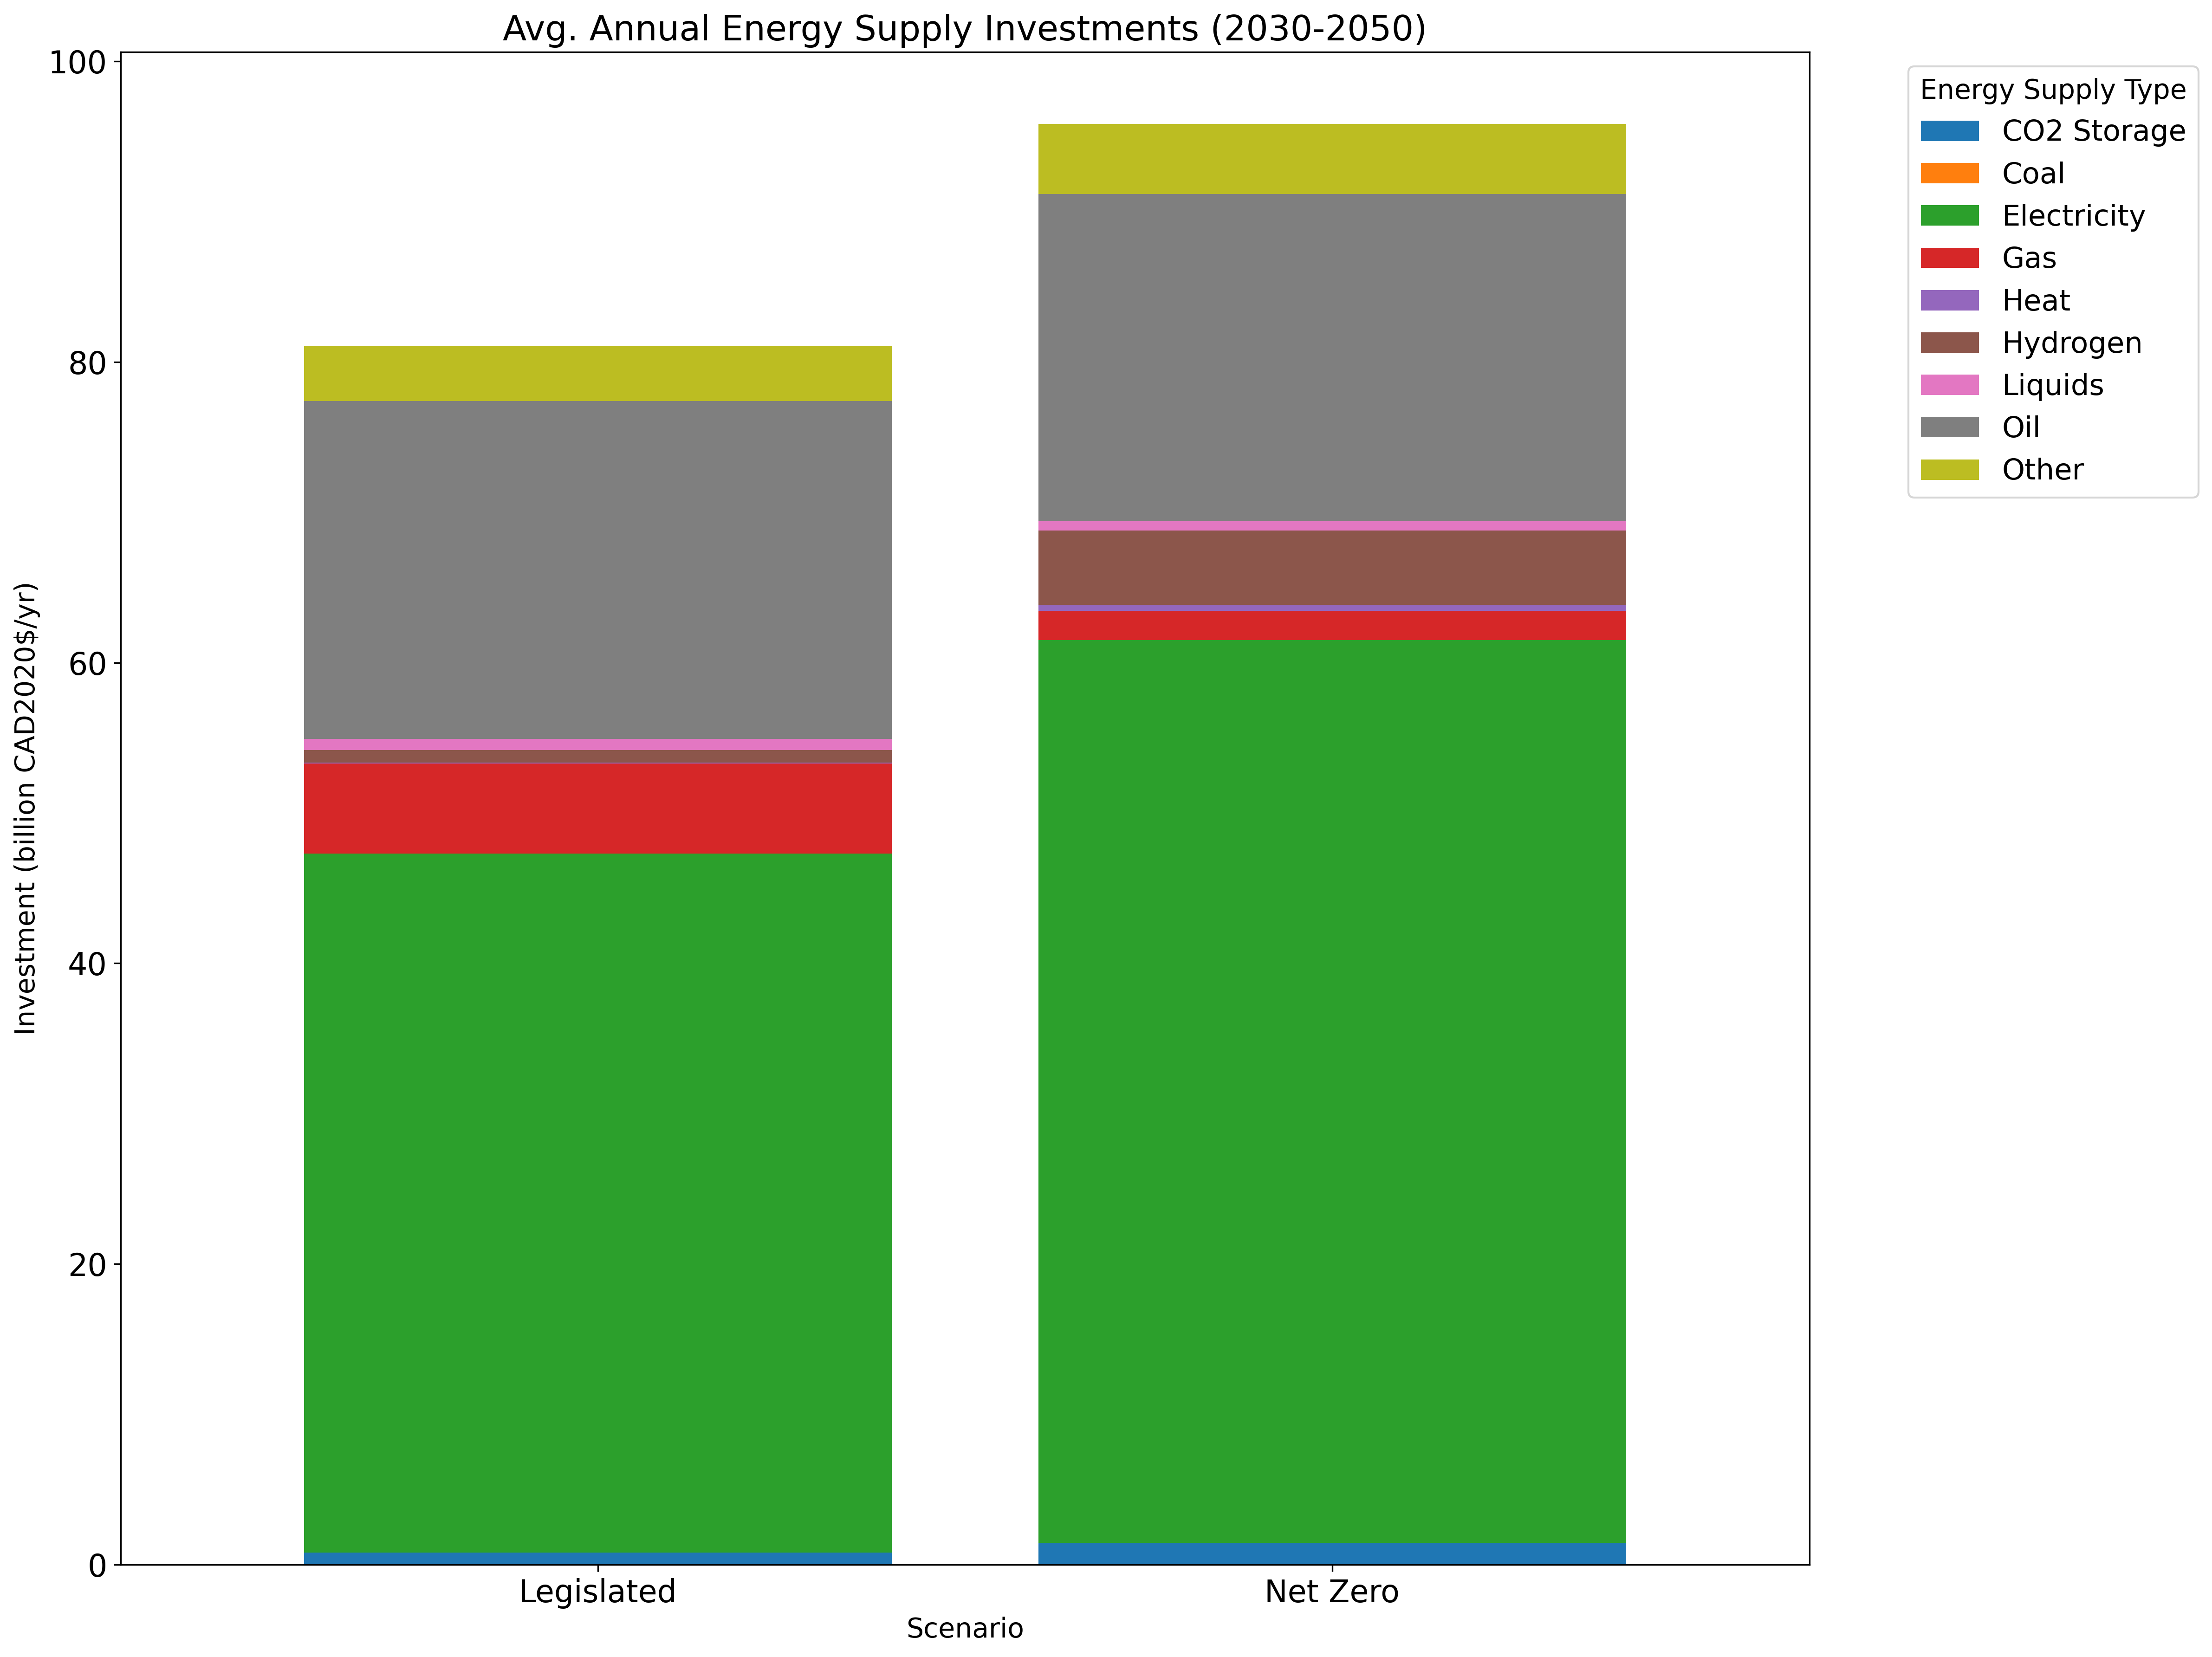

In [5]:
# Re-importing necessary libraries as the environment was reset
import pandas as pd
import matplotlib.pyplot as plt

# Reloading the file and processing it
file_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/notebooks/plot_inv.csv'
data = pd.read_csv(file_path)

# Simplify the variable names for meaningful legends
data['variable'] = data['variable'].str.replace('Investment|Energy Supply|', '', regex=False)
data['variable'] = data['variable'].str.replace('Extraction|', '', regex=False)
data['variable'] = data['variable'].str.replace('CO2 Transport and Storage', 'CO2 Storage', regex=False)
data['variable'] = data['variable'].str.replace('|', ' ', regex=False).str.strip()

# Filter the data to include only the specified scenarios
filtered_data = data[data['scenario'].isin(['BAU', 'NZ-OPT'])]

# Update the scenario names for meaningful labels
filtered_data['scenario'] = filtered_data['scenario'].replace({'BAU': 'Legislated', 'NZ-OPT': 'Net Zero'})

# Prepare the data for stacked bar chart
stacked_data = filtered_data.pivot_table(
    index='variable', columns='scenario', values='value', aggfunc='sum'
)

# Plotting the stacked bar chart
fig, ax = plt.subplots(figsize=(16, 12), dpi=300)

stacked_data.T.plot(kind='bar', stacked=True, ax=ax, width=0.8)

# Customize the plot
ax.set_title('Avg. Annual Energy Supply Investments (2030-2050)', fontsize=18)
ax.set_xlabel('Scenario', fontsize=14)
ax.set_ylabel('Investment (billion CAD2020$/yr)', fontsize=14)
ax.legend(title='Energy Supply Type', fontsize=15, title_fontsize=14, bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', labelsize=16, rotation=0)
ax.tick_params(axis='y', labelsize=16)

# Save the stacked bar chart
plt.tight_layout()
# plt.savefig('/mnt/data/stacked_energy_investment_plot.png', format='png', dpi=300)
plt.show()
